In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import spacy

# Load dataset
df = pd.read_csv("fakenews.csv")

In [2]:
# Load English language model
nlp = spacy.load("en_core_web_sm")

# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display dataset
print(df[["label", "text"]].head())

print("\nTotal articles:", len(df))

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...

Total articles: 2212


In [3]:
# Store sentence-level feature results
sentence_features = []

for index, row in df.iterrows():
    doc = nlp(row["text"])

    # Extract sentences
    sentences = list(doc.sents)

    # Count words in each sentence
    sentence_lengths = [
        len([
            token for token in sent
            if not token.is_punct and not token.is_space
        ])
        for sent in sentences
    ]

    # Calculate average sentence length
    average_sentence_length = (
        sum(sentence_lengths) / len(sentence_lengths)
        if sentence_lengths else 0
    )

    # Calculate lexical richness
    words = [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha
    ]

    lexical_richness = (
        len(set(words)) / len(words)
        if words else 0
    )

    # Count grammatical dependencies
    dependency_count = sum(
        1 for token in doc
        if token.dep_ != "ROOT"
        and not token.is_punct
        and not token.is_space
    )

    # Calculate syntactic complexity
    syntactic_complexity = (
        dependency_count / len(sentences)
        if sentences else 0
    )

    sentence_features.append({
        "news_id": row["news_id"],
        "label": row["label"],
        "sentence_count": len(sentences),
        "average_sentence_length": average_sentence_length,
        "lexical_richness": lexical_richness,
        "syntactic_complexity": syntactic_complexity
    })

# Convert results into a DataFrame
features_df = pd.DataFrame(sentence_features)

print(features_df.head())

   news_id label  sentence_count  average_sentence_length  lexical_richness  \
0        1  Real               1                     15.0          0.866667   
1        2  Real               1                     16.0          1.000000   
2        3  Fake               1                     15.0          1.000000   
3        4  Fake               1                     17.0          0.823529   
4        5  Real               1                     16.0          1.000000   

   syntactic_complexity  
0                  14.0  
1                  15.0  
2                  14.0  
3                  16.0  
4                  15.0  


In [4]:
# Compare average sentence-level features by label
feature_comparison = features_df.groupby("label")[
    [
        "sentence_count",
        "average_sentence_length",
        "lexical_richness",
        "syntactic_complexity"
    ]
].mean()

print("Sentence-Level Feature Comparison:")
print(feature_comparison.round(3))

Sentence-Level Feature Comparison:
       sentence_count  average_sentence_length  lexical_richness  \
label                                                              
Fake            1.235                   13.523             0.958   
Real            1.220                   13.516             0.959   

       syntactic_complexity  
label                        
Fake                 12.523  
Real                 12.516  


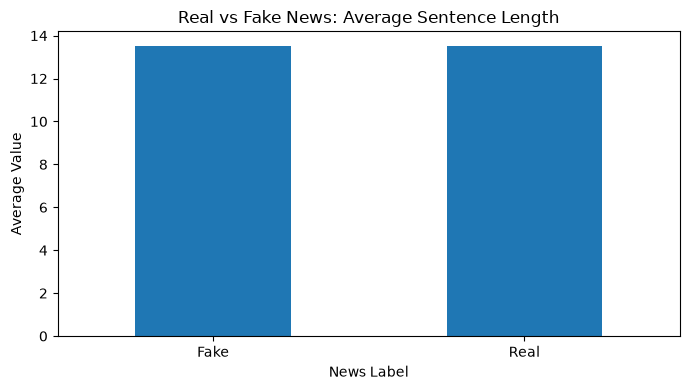

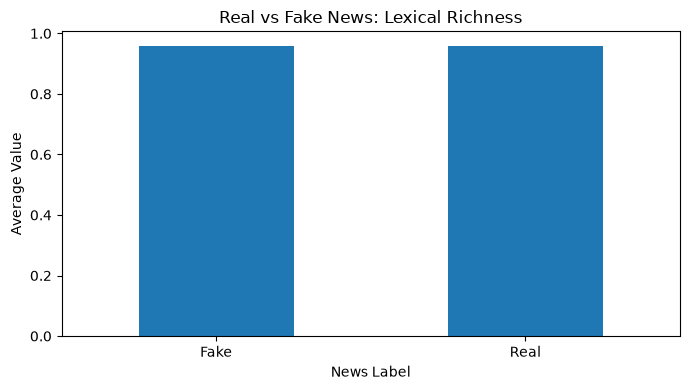

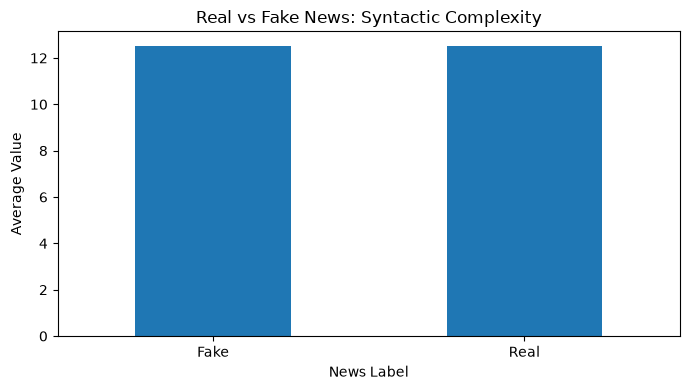

In [5]:
# Plot each feature separately for clearer comparison
features_to_plot = [
    "average_sentence_length",
    "lexical_richness",
    "syntactic_complexity"
]

for feature in features_to_plot:
    feature_comparison[feature].plot(
        kind="bar",
        figsize=(7, 4)
    )

    plt.title(f"Real vs Fake News: {feature.replace('_', ' ').title()}")
    plt.xlabel("News Label")
    plt.ylabel("Average Value")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [6]:
# Save sentence-level features
features_df.to_csv("T18_sentence_level_features.csv", index=False)

# Save Real vs Fake comparison
feature_comparison.to_csv("T18_feature_comparison.csv")

print("Task 18 completed successfully!")

print("\nFiles saved:")
print("1. T18_sentence_level_features.csv")
print("2. T18_feature_comparison.csv")

Task 18 completed successfully!

Files saved:
1. T18_sentence_level_features.csv
2. T18_feature_comparison.csv
